In [1]:
%pip install matplotlib

from pathlib import Path
from collections import Counter
import json
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import re
import pandas as pd
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.


In [2]:
ROOT_DIR = Path.cwd().parent.parent
data_file_path = ROOT_DIR / "data" / "fashion_products_dataset.json" 

with open(data_file_path, "r") as f:
    products = json.load(f)

print(f"Total products loaded：{len(products):,}")

Total products loaded：28,080


In [3]:
attributes = ["pid", "title", "description", "brand", "category", "sub_category", "product_details", "seller", "out_of_stock", 
"selling_price", "discount", "actual_price", "average_rating", "url"]

for attribute in attributes:
    missing_count = sum(1 for product in products if product.get(attribute) == "" or product.get(attribute) is None)
    print(f"{attribute}: {missing_count:,}, missing percentage: {missing_count / len(products) * 100:.2f}%")

pid: 0, missing percentage: 0.00%
title: 0, missing percentage: 0.00%
description: 11,150, missing percentage: 39.71%
brand: 2,009, missing percentage: 7.15%
category: 0, missing percentage: 0.00%
sub_category: 0, missing percentage: 0.00%
product_details: 0, missing percentage: 0.00%
seller: 1,643, missing percentage: 5.85%
out_of_stock: 0, missing percentage: 0.00%
selling_price: 2, missing percentage: 0.01%
discount: 855, missing percentage: 3.04%
actual_price: 777, missing percentage: 2.77%
average_rating: 2,261, missing percentage: 8.05%
url: 0, missing percentage: 0.00%


In [4]:
nltk.download("stopwords", quiet=True, raise_on_error=True)

stop_words = stopwords.words("english")
print(f"First 10 stop words: {stop_words[:10]}")

stop_words = set(stop_words)
stemmer = PorterStemmer()

def preprocess_text(text):
    if not text:
        return []
    
    text = text.lower()
    tokens = re.findall(r"[a-z0-9]+", text)
    
    tokens_removed_stopwords = [token for token in tokens if token not in stop_words]
    tokens_stemmed = [stemmer.stem(token) for token in tokens_removed_stopwords]

    return tokens_stemmed

product = products[0]
print(type(product["product_details"]), product["product_details"])
print(type(product["product_details"][0]), product["product_details"][0])

print(f"Original product title: {product["title"]}")
print(f"Preprocessed product title: {preprocess_text(product["title"])}")

print(f"Original product description: {product["description"]}")
print(f"Preprocessed product description: {preprocess_text(product["description"])}")

First 10 stop words: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']
<class 'list'> [{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Multicolor'}]
<class 'dict'> {'Style Code': '1005COMBO2'}
Original product title: Solid Women Multicolor Track Pants
Preprocessed product title: ['solid', 'women', 'multicolor', 'track', 'pant']
Original product description: Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
Preprocessed product description: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']


In [5]:
""" EDA here """

' EDA here '

In [6]:
attributes = ["category", "sub_category", "brand", "product_details", "seller"]

for attribute in attributes:
    print(f"{attribute}: {products[0].get(attribute)}")


def normalize_attribute(text):
    if not text:
        return ""
    
    return " ".join(text.lower().split())

def product_details_to_text(product_details):
    attribute_texts = []

    for detail in product_details:
        for key, value in detail.items():
            if value is not None:
                attribute_texts.append(f"{key} {value}")

    return " ".join(attribute_texts)

metadata_attributes = ["category", "sub_category", "brand", "seller"]

preprocessed_products = []

for product in products:
    preprocessed_product = product.copy()
    preprocessed_product["title_tokens"] = preprocess_text(product["title"])
    preprocessed_product["description_tokens"] = preprocess_text(product["description"])
    
    for attribute in metadata_attributes:
        preprocessed_product[f"{attribute}_normalized"] = normalize_attribute(product[attribute])

    detail_text = product_details_to_text(product["product_details"])
    preprocessed_product["product_details_tokens"] = preprocess_text(detail_text)
    
    preprocessed_products.append(preprocessed_product)

preprocessed_product = preprocessed_products[0]

print(f"Preprocessed products: {len(preprocessed_products):,}")

print(f"Original product title: {preprocessed_product["title"]}")
print(f"Preprocessed product title: {preprocessed_product["title_tokens"]}")

print(f"Original product description: {preprocessed_product["description"]}")
print(f"Preprocessed product description: {preprocessed_product["description_tokens"]}")

for attribute in metadata_attributes:
    print(f"Original product {attribute}: {preprocessed_product[attribute]}")
    print(f"Normalized product {attribute}: {preprocessed_product[f"{attribute}_normalized"]}")

print(f"Original product details: {preprocessed_product["product_details"]}")
print(f"Preprocessed product details: {preprocessed_product["product_details_tokens"]}")

category: Clothing and Accessories
sub_category: Bottomwear
brand: York
product_details: [{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Multicolor'}]
seller: Shyam Enterprises
Preprocessed products: 28,080
Original product title: Solid Women Multicolor Track Pants
Preprocessed product title: ['solid', 'women', 'multicolor', 'track', 'pant']
Original product description: Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
Preprocessed product description: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']
Original product category: Clothing and Accessories
Normalized product categ

In [7]:
def parse_price(value):
    if value is None:
        return None

    text = value.strip().replace(",", "")

    try:
        price = float(text)
    except ValueError:
        return None

    return price

def parse_discount(value):
    value = value.replace("%", "").replace("off", "").strip()

    discount = parse_price(value)

    if discount is None or not (0 <= discount <= 100):
        return None

    return discount

numerical_attributes = ["selling_price", "actual_price", "average_rating"]

for product in preprocessed_products:
    for attribute in numerical_attributes:
        product[f"{attribute}_numeric"] = parse_price(product[attribute])

    product["discount_numeric"] = parse_discount(product["discount"])

preprocessed_product = preprocessed_products[0]

for attribute in numerical_attributes + ["discount"]:
    print(f"{attribute}: {preprocessed_product[attribute]!r}") # !r let original string be printed with quotes
    print(f"{attribute}_numeric: {preprocessed_product[f'{attribute}_numeric']}")


selling_price: '921'
selling_price_numeric: 921.0
actual_price: '2,999'
actual_price_numeric: 2999.0
average_rating: '3.9'
average_rating_numeric: 3.9
discount: '69% off'
discount_numeric: 69.0


In [8]:
output_file_path = ROOT_DIR / "data" / "preprocessed_fashion_products_dataset.json"

with open(output_file_path, "w", encoding="utf-8") as file:
    json.dump(preprocessed_products, file, ensure_ascii=False, indent=4, allow_nan=False)

print(f"Finished => Preprocessed products saved to: {output_file_path}")

Finished => Preprocessed products saved to: /Users/xia/Documents/University/Recuperació de la Informació i Anàlisi de la Web/Final Project/irwa-search-engine/data/preprocessed_fashion_products_dataset.json


# Part 2: Exploratory Data Analysis

# 2.1 Before and After text lengths

In [9]:
before_after_text_lengths = []
for product in preprocessed_products:
    title = product["title"]
    description = product.get("description") or ""

    before_after_text_lengths.append({
        "title_before": len(re.findall(r"[a-z0-9]+", title.lower())),
        "title_after": len(product["title_tokens"]),
        "description_before": len(re.findall(r"[a-z0-9]+", description.lower())),
        "description_after": len(product["description_tokens"])
    })

lengths_df = pd.DataFrame(before_after_text_lengths)
lengths_df.describe().round(2)

,title_before,title_after,description_before,description_after
count,28080.00,28080.00,28080.00,28080.00
mean,6.93,6.27,30.71,18.84
std,2.35,1.98,45.84,26.72
min,1.00,1.00,0.00,0.00
25%,6.00,5.00,0.00,0.00
50%,7.00,6.00,11.00,9.00
75%,8.00,7.00,50.00,29.00
max,36.00,31.00,693.00,579.00


# Vocabulary and Frequent Tokens

Total tokens: 705,276
Vocabulary size: 4,902
Top 10 tokens: [('shirt', 34159), ('women', 17570), ('men', 16835), ('neck', 14943), ('print', 13011), ('cotton', 11795), ('solid', 10624), ('round', 10197), ('fit', 9754), ('wear', 9370)]


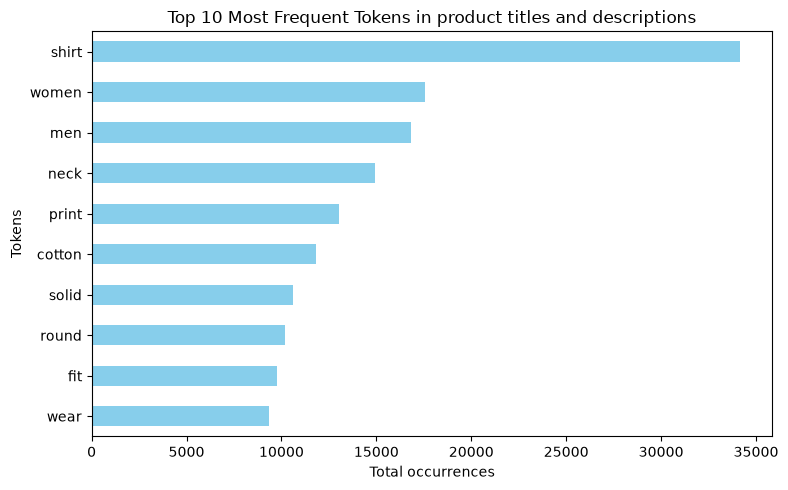

In [10]:
token_count = Counter()

for product in preprocessed_products:
    token_count.update(product["title_tokens"])
    token_count.update(product["description_tokens"])

total_tokens = sum(token_count.values())
vocabulary_size = len(token_count)

print(f"Total tokens: {total_tokens:,}")
print(f"Vocabulary size: {vocabulary_size:,}")

top_10_tokens = token_count.most_common(10)
print(f"Top 10 tokens: {top_10_tokens}")

top_10_tokens_df = pd.DataFrame(top_10_tokens, columns=["token", "count"])

top_10_tokens_df

top_10_tokens_df.sort_values("count").plot.barh(
    x="token", 
    y="count", 
    legend=False, 
    figsize=(8, 5), 
    color="skyblue", 
    )

plt.title("Top 10 Most Frequent Tokens in product titles and descriptions")
plt.xlabel("Total occurrences")
plt.ylabel("Tokens")
plt.tight_layout()
plt.show()


# Prices, Discounts and Ratings

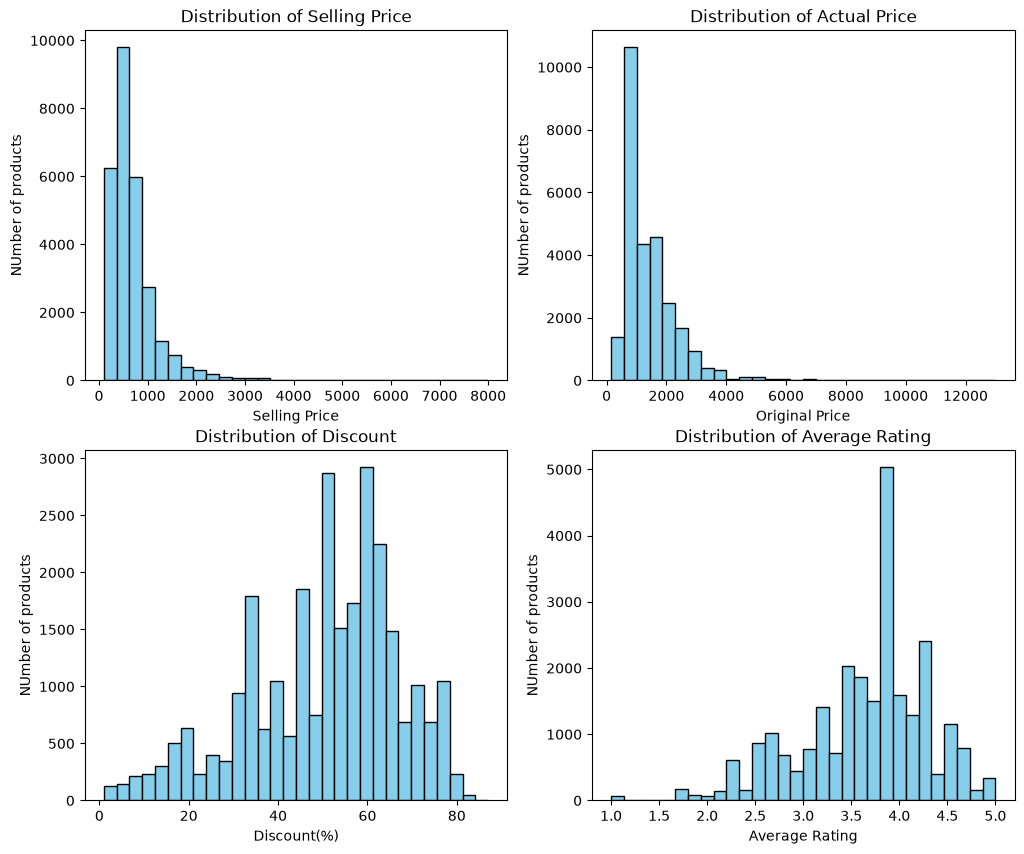

In [11]:
numeric_attributes = ["selling_price_numeric", "actual_price_numeric", "discount_numeric", "average_rating_numeric"]

numeric_df = pd.DataFrame([
    {attribute: product[attribute] for attribute in numeric_attributes}
    for product in preprocessed_products  
])

numeric_df.describe().round(2)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
plot_titles = [
    ("selling_price_numeric", "Distribution of Selling Price", "Selling Price"),
    ("actual_price_numeric", "Distribution of Actual Price", "Original Price"),
    ("discount_numeric", "Distribution of Discount", "Discount(%)"),
    ("average_rating_numeric", "Distribution of Average Rating", "Average Rating")
]

for ax, (attribute, title, xlabel) in zip(axes.flatten(), plot_titles):
    ax.hist(
        numeric_df[attribute].dropna(), 
        bins=30, 
        color="skyblue", 
        edgecolor="black"
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("NUmber of products")

# CAtegories, brands and sellers

category
Valid counts: Counter({'clothing and accessories': 27118, 'footwear': 920, 'bags, wallets & belts': 41, 'toys': 1})
Missing counts: 0
sub_category
Valid counts: Counter({'topwear': 15310, 'bottomwear': 3666, 'winter wear': 2493, 'innerwear and swimwear': 1762, 'clothing accessories': 1742, 'kurtas, ethnic sets and bottoms': 1180, "men's footwear": 920, 'fabrics': 534, 'sleepwear': 122, 'blazers, waistcoats and suits': 103, 'tracksuits': 90, 'raincoats': 34, 'sunshopping bags, wallets & belts': 31, 'uber urban clothing and accessories': 28, 'inspire clothing and accessories': 27, 'crocks club clothing and accessories': 15, 'roy clothing and accessories': 12, 'winsome deal bags, wallets & belts': 4, 'yofama bags, wallets & belts': 4, 'party supplies': 1, 'brand trunk bags, wallets & belts': 1, 'mentiezi bags, wallets & belts': 1})
Missing counts: 0
brand
Valid counts: Counter({'ecko unl': 951, 'free authori': 860, 'arbo': 806, 'reeb': 802, 'pu': 798, 'true bl': 793, 'keo': 660, 

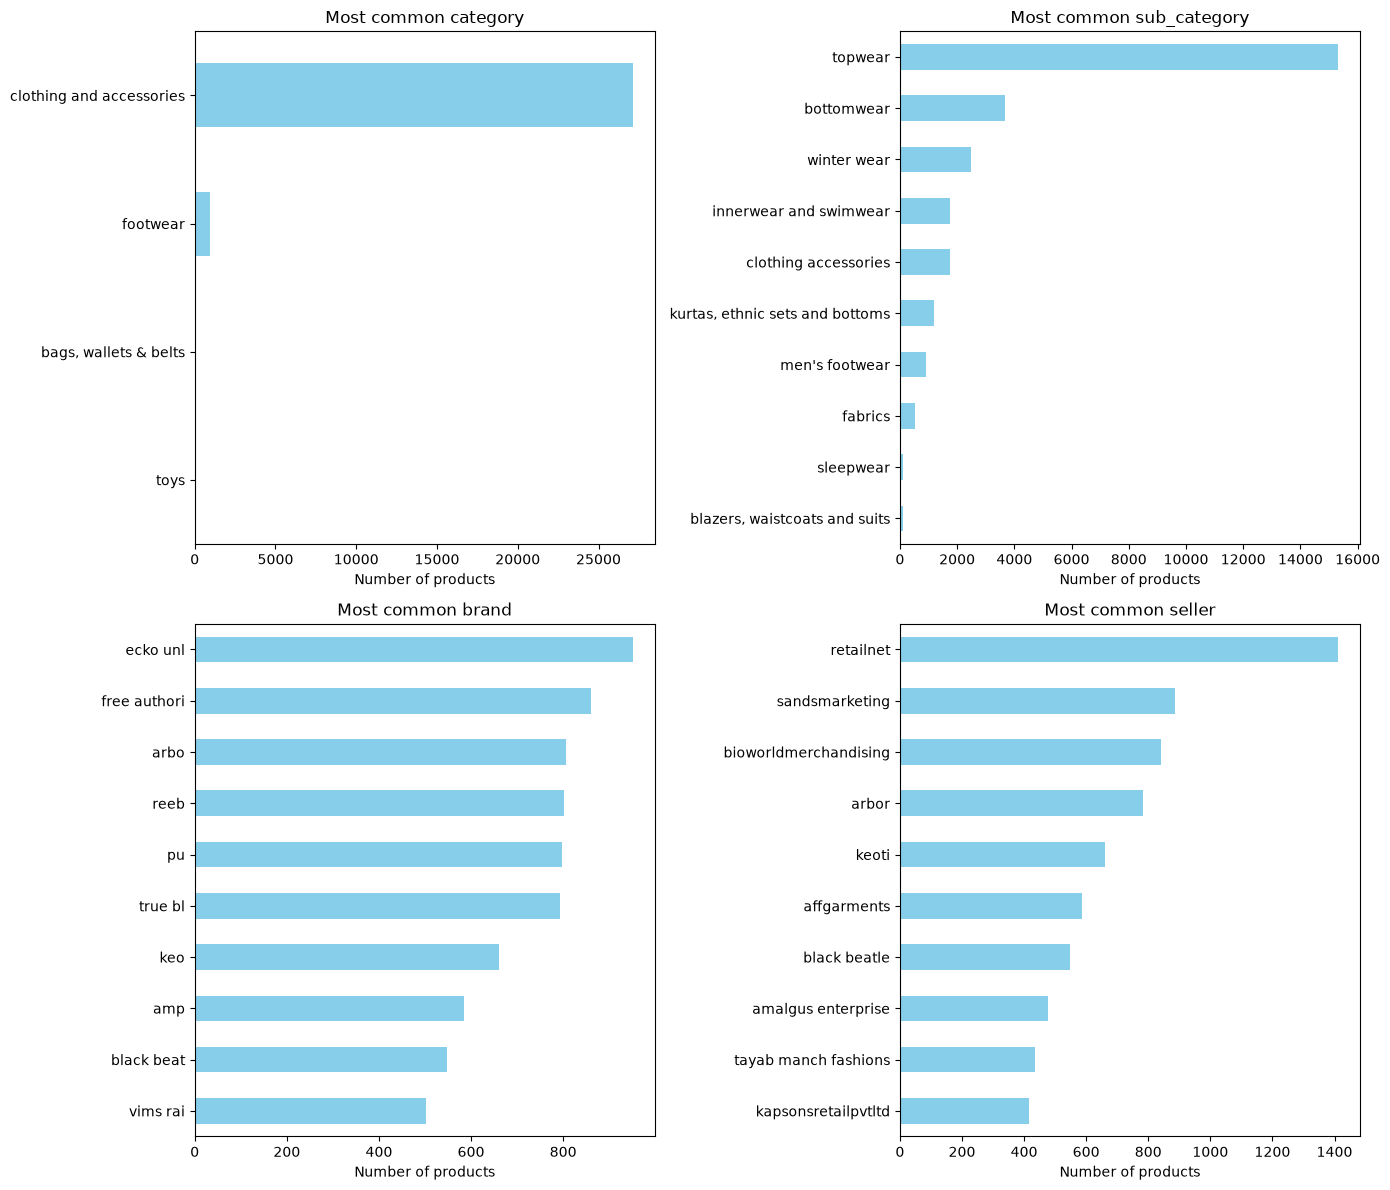

In [12]:
metadata_attributes = ["category", "sub_category", "brand", "seller"]

metadata_counts = {}

for attribute in metadata_attributes:
    values = [product[f"{attribute}_normalized"] for product in preprocessed_products]

    missing_count = values.count("")
    values = [value for value in values if value != ""]

    counts = Counter(values)
    metadata_counts[attribute] = counts

    print(f"{attribute}")
    print(f"Valid counts: {counts}")
    print(f"Missing counts: {missing_count}")

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, attribute in zip(axes.flatten(), metadata_attributes):
    top_values_df = pd.DataFrame(metadata_counts[attribute].most_common(10),
                                 columns=[attribute, "product_count"])

    top_values_df.sort_values("product_count").plot.barh(
        x=attribute,
        y="product_count",
        ax=ax,
        legend=False,
        color="skyblue"
    )

    ax.set_title(f"Most common {attribute}")
    ax.set_xlabel("Number of products")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

# Out of Stock

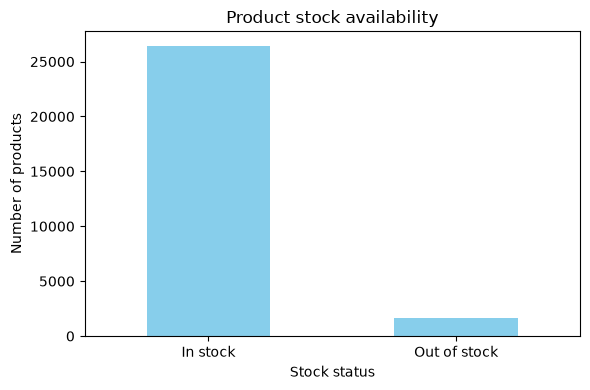

In [13]:
stock_count = Counter(
    product["out_of_stock"]
    for product in preprocessed_products
)

stock_df = pd.DataFrame([
    {
        "stock_status": "Out of stock" if status else "In stock",
        "product_count": count,
        "percentage": count / len(preprocessed_products) * 100
    }

    for status, count in stock_count.items()
])

stock_df.round(2)

stock_df.plot.bar(
    x="stock_status",
    y="product_count",
    color="skyblue",
    figsize=(6, 4),
    rot=0,
    legend=False
)

plt.title("Product stock availability")
plt.xlabel("Stock status")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()